In [1]:
# ============================================================
# 1. LIBRERÍAS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

In [2]:
# ============================================================
# 2. IMPORTAR DATASET LOCAL
# ============================================================

ruta = "02-22-2018.csv"   

df = pd.read_csv(ruta)

print("Dimensiones del dataset:", df.shape)
df.head()

Dimensiones del dataset: (1048575, 80)


,Dst Port,Protocol,Timestamp,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Pkt Len Min,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,22,6,22/02/2018 08:26:03,20553406,10,7,1063,1297,744,0,...,20,1027304.0,0.0,1027304,1027304,1.952608e+07,0.000000e+00,19526080,19526080,Benign
1,34989,6,22/02/2018 08:26:24,790,2,0,848,0,848,0,...,20,0.0,0.0,0,0,0.000000e+00,0.000000e+00,0,0,Benign
2,500,17,22/02/2018 08:25:10,99745913,5,0,2500,0,500,500,...,8,4000203.0,0.0,4000203,4000203,3.191524e+07,3.792787e+07,75584115,7200679,Benign
3,500,17,22/02/2018 08:25:10,99745913,5,0,2500,0,500,500,...,8,4000189.0,0.0,4000189,4000189,3.191524e+07,3.792788e+07,75584130,7200693,Benign
4,500,17,22/02/2018 08:24:59,89481361,6,0,3000,0,500,500,...,8,4000554.0,0.0,4000554,4000554,2.137020e+07,1.528109e+07,41990741,7200848,Benign


In [4]:
# ============================================================
# 3. LIMPIEZA INICIAL
# ============================================================

# Eliminar espacios en nombres de columnas
df.columns = df.columns.str.strip()

# Mostrar columnas
df.columns

Index(['Dst Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Tot Fwd Pkts',
       'Tot Bwd Pkts', 'TotLen Fwd Pkts', 'TotLen Bwd Pkts', 'Fwd Pkt Len Max',
       'Fwd Pkt Len Min', 'Fwd Pkt Len Mean', 'Fwd Pkt Len Std',
       'Bwd Pkt Len Max', 'Bwd Pkt Len Min', 'Bwd Pkt Len Mean',
       'Bwd Pkt Len Std', 'Flow Byts/s', 'Flow Pkts/s', 'Flow IAT Mean',
       'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Tot',
       'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min',
       'Bwd IAT Tot', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max',
       'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags',
       'Bwd URG Flags', 'Fwd Header Len', 'Bwd Header Len', 'Fwd Pkts/s',
       'Bwd Pkts/s', 'Pkt Len Min', 'Pkt Len Max', 'Pkt Len Mean',
       'Pkt Len Std', 'Pkt Len Var', 'FIN Flag Cnt', 'SYN Flag Cnt',
       'RST Flag Cnt', 'PSH Flag Cnt', 'ACK Flag Cnt', 'URG Flag Cnt',
       'CWE Flag Count', 'ECE Flag Cnt', 'Down/Up Ratio', 'Pkt Size Avg',
      

In [5]:
# Verificar valores faltantes
faltantes = df.isnull().sum().sort_values(ascending=False)
faltantes[faltantes > 0]

Flow Byts/s    3569
dtype: int64

In [6]:
# Reemplazar infinitos por NaN
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Eliminar filas con valores NaN
df.dropna(inplace=True)

print("Dimensiones después de limpieza:", df.shape)

Dimensiones después de limpieza: (1042965, 80)


In [7]:
# Verificar columna objetivo
df["Label"].value_counts()

Label
Benign              1042603
Brute Force -Web        249
Brute Force -XSS         79
SQL Injection            34
Name: count, dtype: int64

In [8]:
# ============================================================
# 4. ANÁLISIS EXPLORATORIO DE DATOS - EDA
# ============================================================

df.describe().T

,count,mean,std,min,25%,50%,75%,max
Dst Port,1042965.0,8.752359e+03,1.789570e+04,0.000000e+00,53.0,443.0,3389.0,6.553300e+04
Protocol,1042965.0,9.134065e+00,5.121920e+00,0.000000e+00,6.0,6.0,17.0,1.700000e+01
Flow Duration,1042965.0,1.501515e+07,1.479437e+09,-8.282200e+11,550.0,87092.0,5285896.0,1.200000e+08
Tot Fwd Pkts,1042965.0,6.389820e+00,7.153446e+01,1.000000e+00,1.0,2.0,8.0,1.147800e+04
Tot Bwd Pkts,1042965.0,8.269380e+00,2.041391e+02,0.000000e+00,0.0,1.0,7.0,3.841800e+04
...,...,...,...,...,...,...,...,...
Active Min,1042965.0,4.532498e+04,5.906291e+05,0.000000e+00,0.0,0.0,0.0,1.084622e+08
Idle Mean,1042965.0,1.176179e+07,8.838182e+08,0.000000e+00,0.0,0.0,0.0,3.955714e+11
Idle Std,1042965.0,1.594229e+06,5.465995e+08,0.000000e+00,0.0,0.0,0.0,2.622479e+11
Idle Max,1042965.0,1.460546e+07,1.937596e+09,0.000000e+00,0.0,0.0,0.0,9.684340e+11


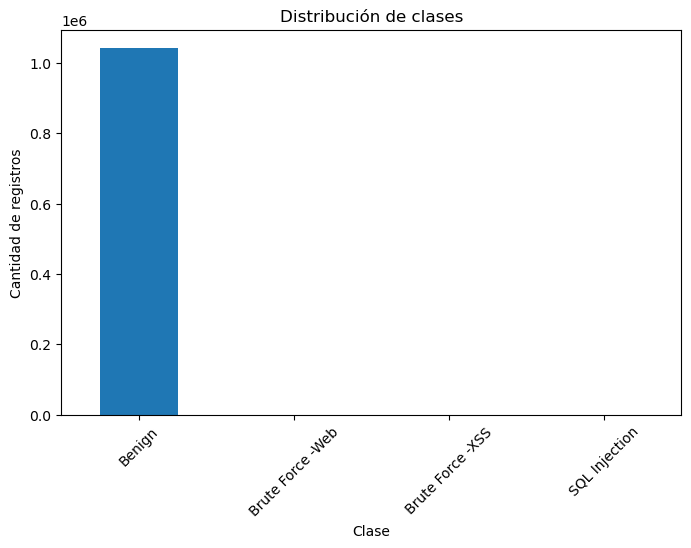

In [9]:
# Distribución de clases

plt.figure(figsize=(8,5))
df["Label"].value_counts().plot(kind="bar")
plt.title("Distribución de clases")
plt.xlabel("Clase")
plt.ylabel("Cantidad de registros")
plt.xticks(rotation=45)
plt.show()

In [10]:
# Porcentaje de cada clase

porcentaje_clases = df["Label"].value_counts(normalize=True) * 100
porcentaje_clases

Label
Benign              99.965291
Brute Force -Web     0.023874
Brute Force -XSS     0.007575
SQL Injection        0.003260
Name: proportion, dtype: float64

In [11]:
# Seleccionar solo columnas numéricas

df_numeric = df.select_dtypes(include=[np.number])

print("Cantidad de variables numéricas:", df_numeric.shape[1])
df_numeric.head()


Cantidad de variables numéricas: 78


,Dst Port,Protocol,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Pkt Len Min,Fwd Pkt Len Mean,...,Fwd Act Data Pkts,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
0,22,6,20553406,10,7,1063,1297,744,0,106.3,...,4,20,1027304.0,0.0,1027304,1027304,1.952608e+07,0.000000e+00,19526080,19526080
1,34989,6,790,2,0,848,0,848,0,424.0,...,0,20,0.0,0.0,0,0,0.000000e+00,0.000000e+00,0,0
2,500,17,99745913,5,0,2500,0,500,500,500.0,...,4,8,4000203.0,0.0,4000203,4000203,3.191524e+07,3.792787e+07,75584115,7200679
3,500,17,99745913,5,0,2500,0,500,500,500.0,...,4,8,4000189.0,0.0,4000189,4000189,3.191524e+07,3.792788e+07,75584130,7200693
4,500,17,89481361,6,0,3000,0,500,500,500.0,...,5,8,4000554.0,0.0,4000554,4000554,2.137020e+07,1.528109e+07,41990741,7200848


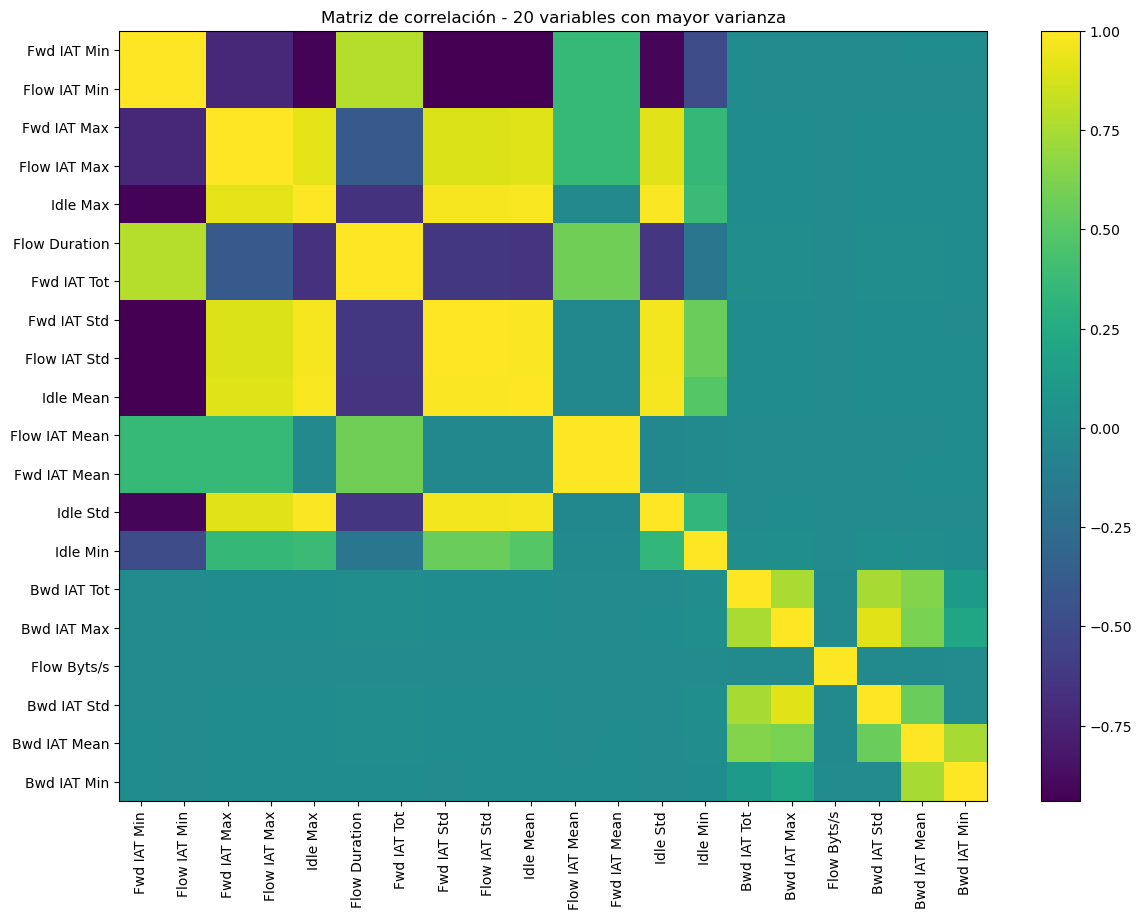

In [12]:
# Matriz de correlación de las 20 variables más variables

top_var = df_numeric.var().sort_values(ascending=False).head(20).index

plt.figure(figsize=(14,10))
corr = df_numeric[top_var].corr()
plt.imshow(corr, aspect='auto')
plt.colorbar()
plt.xticks(range(len(top_var)), top_var, rotation=90)
plt.yticks(range(len(top_var)), top_var)
plt.title("Matriz de correlación - 20 variables con mayor varianza")
plt.show()

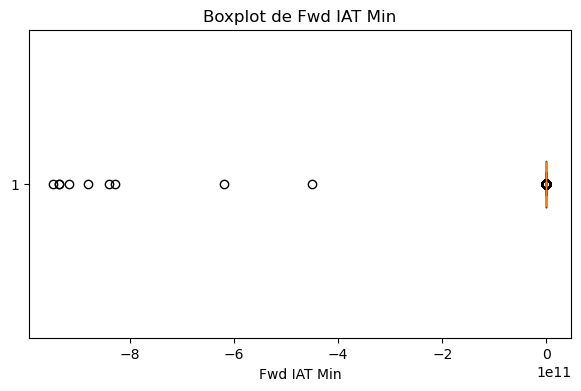

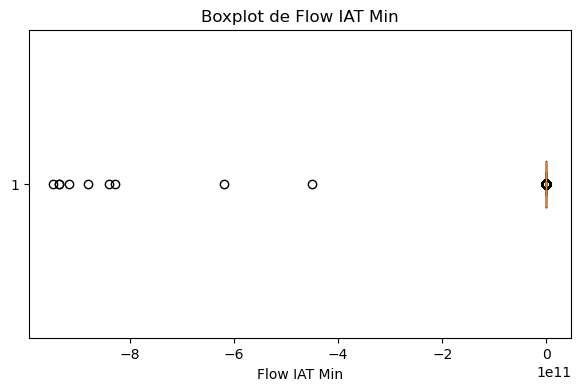

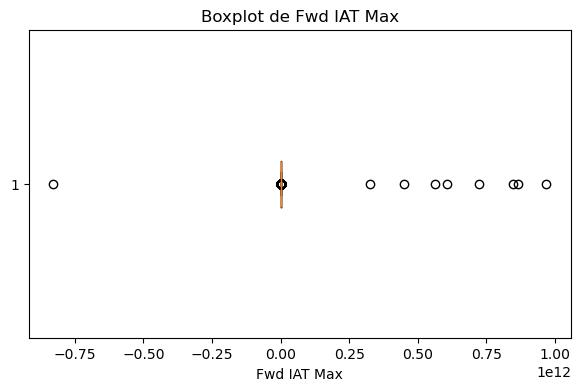

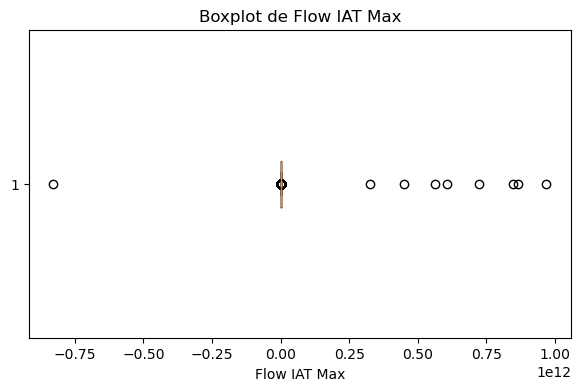

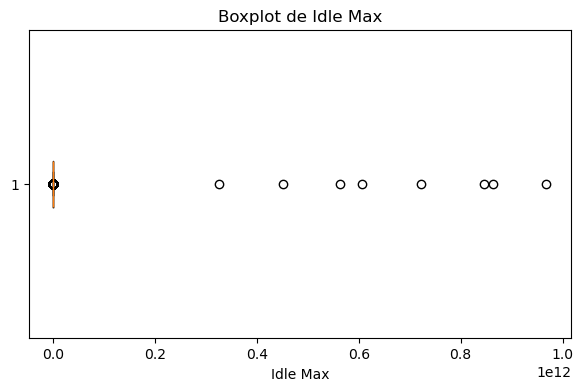

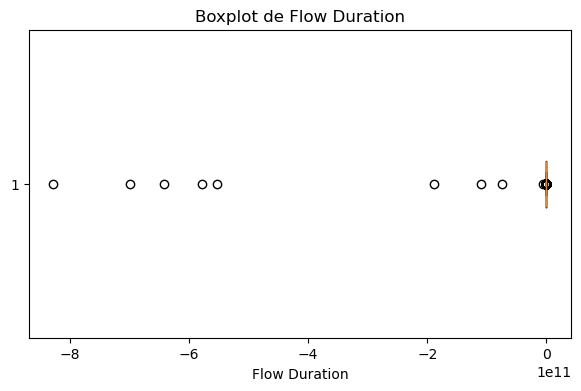

In [13]:
# Boxplot para detectar posibles anomalías en algunas variables

variables_boxplot = top_var[:6]

for col in variables_boxplot:
    plt.figure(figsize=(7,4))
    plt.boxplot(df_numeric[col], vert=False)
    plt.title(f"Boxplot de {col}")
    plt.xlabel(col)
    plt.show()

C:\Users\Usuario\anaconda3\envs\ids2018\lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


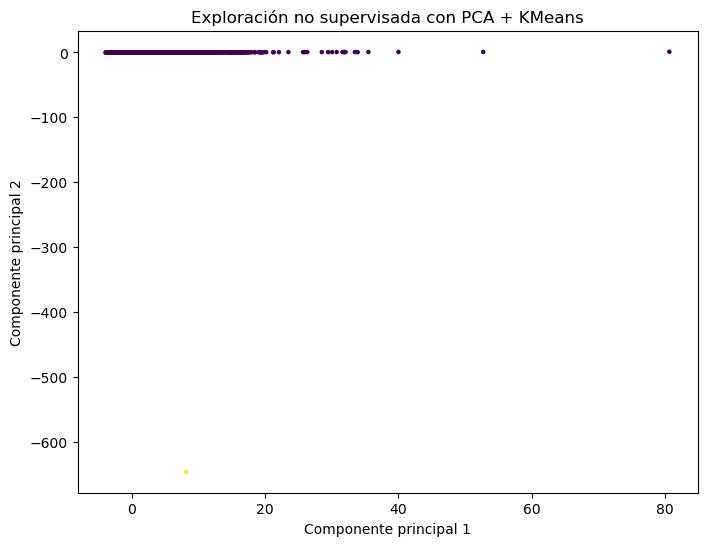

Varianza explicada por PCA: [0.2068026  0.20442909]


In [14]:
# ============================================================
# 5. EXPLORACIÓN NO SUPERVISADA CON PCA + KMEANS
# ============================================================

# Tomar muestra para evitar sobrecarga si el dataset es muy grande
df_sample = df.sample(n=min(30000, len(df)), random_state=42)

X_unsup = df_sample.select_dtypes(include=[np.number])

scaler_unsup = StandardScaler()
X_unsup_scaled = scaler_unsup.fit_transform(X_unsup)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_unsup_scaled)

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_pca)

plt.figure(figsize=(8,6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, s=5)
plt.title("Exploración no supervisada con PCA + KMeans")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.show()

print("Varianza explicada por PCA:", pca.explained_variance_ratio_)

In [15]:
# ============================================================
# 6. PREPROCESAMIENTO PARA MACHINE LEARNING
# ============================================================

# Codificar la variable objetivo
le = LabelEncoder()
df["Label_encoded"] = le.fit_transform(df["Label"])

print("Clases codificadas:")
for clase, codigo in zip(le.classes_, range(len(le.classes_))):
    print(codigo, "=", clase)

Clases codificadas:
0 = Benign
1 = Brute Force -Web
2 = Brute Force -XSS
3 = SQL Injection


In [16]:
# Separar variables predictoras y objetivo

X = df.drop(columns=["Label", "Label_encoded"], errors="ignore")
y = df["Label_encoded"]

# Conservar solo variables numéricas
X = X.select_dtypes(include=[np.number])

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Dimensiones de X: (1042965, 78)
Dimensiones de y: (1042965,)


In [17]:
# División entrenamiento/prueba

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

Entrenamiento: (730075, 78)
Prueba: (312890, 78)


In [18]:
# Escalamiento para modelos sensibles a escala

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [19]:
# ============================================================
# 7. MODELOS DE MACHINE LEARNING
# ============================================================

modelos = { ### Permite interpretar reglas de decisión y detectar variables relevantes.
            #### ventaja: Fácil interpretación, bajo costo computacional.
            #### limitaciones: Puede sobreajustarse si no se controla la profundidad
    "Árbol de Decisión": DecisionTreeClassifier(
        random_state=42,
        max_depth=20,
        class_weight="balanced"
    ),
        ### Combina múltiples árboles para mejorar la generalización y reducir el sobreajuste
                #### ventaja: Alto desempeño, robusto frente a ruido y variables irrelevantes.
            #### limitaciones: Menos interpretable que un árbol individual
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        max_depth=20,
        class_weight="balanced",
        n_jobs=-1
    ),
      ##### Similar a Random Forest, pero introduce mayor aleatoriedad, lo que puede mejorar el desempeño y reducir varianza
                #### ventaja: Rápido, robusto y eficiente en datasets grandes.
            #### limitaciones: Puede ser menos interpretable y depender de muchas variables
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=100,
        random_state=42,
        max_depth=20,
        class_weight="balanced",
        n_jobs=-1
    ),
     ###### Modelo lineal útil como referencia. Permite evaluar si las clases pueden separarse mediante relaciones lineales
                #### ventaja: Simple, rápido e interpretable.
            #### limitaciones: Puede tener bajo desempeño si las relaciones son no lineales
    "Regresión Logística": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        n_jobs=-1
    )
}

In [20]:
# ============================================================
# 8. ENTRENAMIENTO Y EVALUACIÓN
# ============================================================

resultados = []

predicciones = {}

for nombre, modelo in modelos.items():
    
    print(f"Entrenando modelo: {nombre}")
    
    if nombre == "Regresión Logística":
        modelo.fit(X_train_scaled, y_train)
        y_pred = modelo.predict(X_test_scaled)
    else:
        modelo.fit(X_train, y_train)
        y_pred = modelo.predict(X_test)
    
    predicciones[nombre] = y_pred
    
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
    recall = recall_score(y_test, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)
    
    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    })

df_resultados = pd.DataFrame(resultados)
df_resultados

Entrenando modelo: Árbol de Decisión
Entrenando modelo: Random Forest
Entrenando modelo: Extra Trees
Entrenando modelo: Regresión Logística


,Modelo,Accuracy,Precision,Recall,F1-score
0,Árbol de Decisión,0.999952,0.999957,0.999952,0.999954
1,Random Forest,0.999933,0.999929,0.999933,0.999926
2,Extra Trees,0.946611,0.999727,0.946611,0.972319
3,Regresión Logística,0.942229,0.999655,0.942229,0.969950


In [21]:
# Ordenar resultados por F1-score

df_resultados = df_resultados.sort_values(by="F1-score", ascending=False)
df_resultados

,Modelo,Accuracy,Precision,Recall,F1-score
0,Árbol de Decisión,0.999952,0.999957,0.999952,0.999954
1,Random Forest,0.999933,0.999929,0.999933,0.999926
2,Extra Trees,0.946611,0.999727,0.946611,0.972319
3,Regresión Logística,0.942229,0.999655,0.942229,0.969950


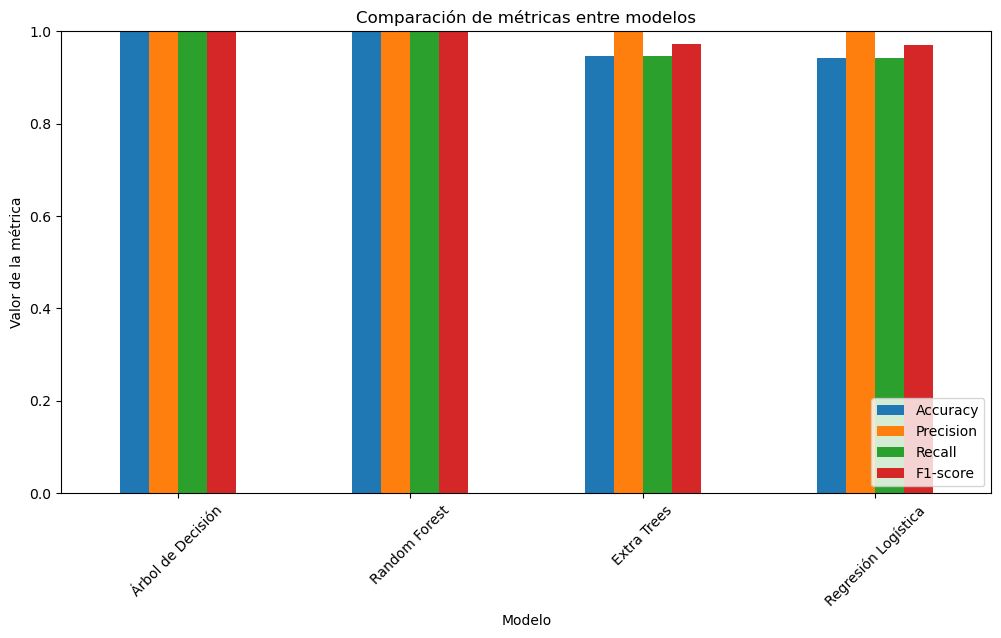

In [22]:
# ============================================================
# 9. GRÁFICO COMPARATIVO DE MÉTRICAS
# ============================================================

df_resultados.set_index("Modelo")[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind="bar",
    figsize=(12,6)
)

plt.title("Comparación de métricas entre modelos")
plt.ylabel("Valor de la métrica")
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.legend(loc="lower right")
plt.show()


Interpretación:

El modelo con mejor desempeño fue: arbol de decisión.

La comparación se realizó usando Accuracy, Precision, Recall y F1-score.

El F1-score es especialmente importante cuando existe desbalance entre clases, porque combina precisión y sensibilidad en una sola métrica.

In [23]:
# ============================================================
# 10. REPORTE DE CLASIFICACIÓN DEL MEJOR MODELO
# ============================================================

mejor_modelo = df_resultados.iloc[0]["Modelo"]

print("Mejor modelo:", mejor_modelo)

print(classification_report(
    y_test,
    predicciones[mejor_modelo],
    target_names=le.classes_,
    zero_division=0
))

Mejor modelo: Árbol de Decisión
                  precision    recall  f1-score   support

          Benign       1.00      1.00      1.00    312781
Brute Force -Web       0.95      0.95      0.95        75
Brute Force -XSS       0.91      0.83      0.87        24
   SQL Injection       0.46      0.60      0.52        10

        accuracy                           1.00    312890
       macro avg       0.83      0.84      0.83    312890
    weighted avg       1.00      1.00      1.00    312890



<Figure size 800x600 with 0 Axes>

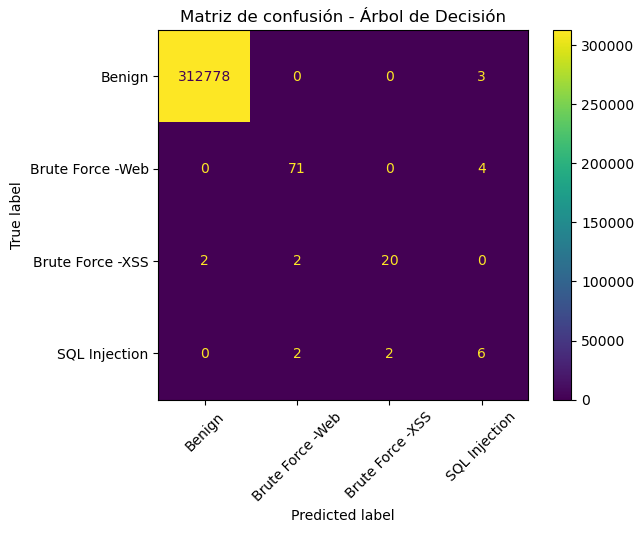

In [24]:
# ============================================================
# 11. MATRIZ DE CONFUSIÓN DEL MEJOR MODELO
# ============================================================

cm = confusion_matrix(y_test, predicciones[mejor_modelo])

plt.figure(figsize=(8,6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=le.classes_
)
disp.plot(cmap=None, xticks_rotation=45)
plt.title(f"Matriz de confusión - {mejor_modelo}")
plt.show()

,Variable,Importancia
66,Init Fwd Win Byts,0.227544
0,Dst Port,0.154107
13,Bwd Pkt Len Mean,0.119740
7,Fwd Pkt Len Max,0.113661
30,Bwd IAT Min,0.102984
20,Flow IAT Min,0.098927
25,Fwd IAT Min,0.070931
37,Fwd Pkts/s,0.023301
38,Bwd Pkts/s,0.021412
27,Bwd IAT Mean,0.017030


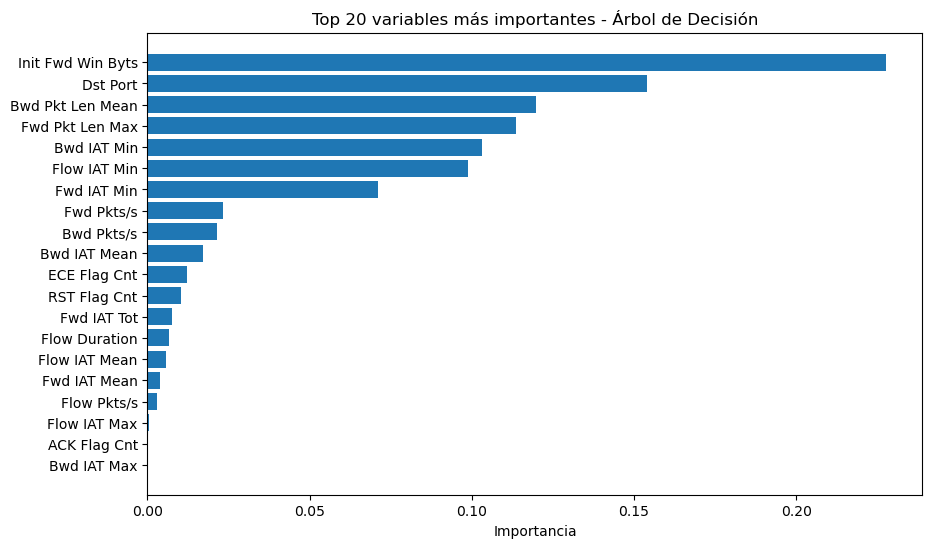

In [25]:
# ============================================================
# 12. IMPORTANCIA DE VARIABLES
# ============================================================

modelo_final = modelos[mejor_modelo]

if hasattr(modelo_final, "feature_importances_"):
    importancias = pd.DataFrame({
        "Variable": X.columns,
        "Importancia": modelo_final.feature_importances_
    }).sort_values(by="Importancia", ascending=False)
    
    display(importancias.head(20))
    
    plt.figure(figsize=(10,6))
    plt.barh(importancias.head(20)["Variable"], importancias.head(20)["Importancia"])
    plt.gca().invert_yaxis()
    plt.title(f"Top 20 variables más importantes - {mejor_modelo}")
    plt.xlabel("Importancia")
    plt.show()
else:
    print("El modelo seleccionado no permite calcular importancia de variables directamente.")

Las mas significativas: 

Número de bytes enviados en la ventana inicial en la dirección de avance

Puerto destino

Tamaño medio del paquete en dirección hacia atrás

Tamaño máximo del paquete en dirección directa

Tiempo mínimo entre dos flujos


# Aplicación:

 Ambientes de seguridad de la información. 
 
 seguridad de redes de datos 
 
 Optimización de Firewall basados en IA .. 
 
 Aplicaciones domésticas mejoradas. 
 
 Limitacion en aplicaciones domesticas, implica la gestion centralizada del trafico de red. 

# Conclusiones: 

 Aun con el desbalance de clases .. se evidencia una alta efectividad del mejor modelo (ARBOL DE DECISIÓN).  
 
 Limitaciones importantes con la capacidad de computo local.
 
 Es importante comparar con los modelos no supervisados.
 
 se debe avanzar en el analisis con el dataset completo. 

